# 07 · RAG — answering questions from filings, with citations and refusals

Stage 5 found the right paragraph. This finds the right *answer*, says which
filing it came from, and — the part that matters — refuses when the corpus
cannot answer.

### Why refusal is the headline feature

A retrieval system that returns the wrong paragraph is annoying. An answering
system that returns a confident, fluent, wrong sentence about a company's debt
covenants is dangerous, because nothing in the output signals it was invented.
**Fluency is not evidence.** So this stage is built around three properties:

| property | what it means | how it is checked |
|---|---|---|
| **grounded** | every sentence traces to a specific passage | verbatim containment, must be 1.00 in extractive mode |
| **attributed** | CIK, ticker, year and passage id on every answer | attribution@1 against the known gold passage |
| **abstaining** | says "I can't answer that" instead of guessing | ROC-AUC on answerable vs unanswerable questions |

### The two modes

**Extractive** (default) selects the sentences from retrieved passages that
best match the question. It *cannot* hallucinate — the answer is a span of the
source. The worst it can do is pick the wrong sentence, which is visible.

**Generative** runs `flan-t5-base` (~250 MB, CPU) over the retrieved context.
It *can* hallucinate. That is the point: with extractive as a 100%-grounded
reference, the generative grounding rate becomes a measurement rather than a
guess. Skip it if you would rather not wait — everything else works without.

In [1]:
import warnings, importlib, json, pickle, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

import config, viz, rag, rag_eval
importlib.reload(rag); importlib.reload(rag_eval)
from rag import RagPipeline, grounded_verbatim, grounding_overlap, unsupported_terms
from rag_eval import (build_unanswerable, evaluate_rag, report_table,
                      threshold_sweep, pick_threshold,
                      report_at_threshold)
viz.use_style()

chunks = pd.read_parquet(config.PROCESSED / "chunks.parquet")
queries_all = pd.read_parquet(config.PROCESSED / "heading_queries.parquet")
emb = np.load(config.PROCESSED / "chunk_embeddings.npy")
meta = json.loads((config.PROCESSED / "index_meta.json").read_text())
with open(config.PROCESSED / "bm25.pkl", "rb") as f:
    bm25 = pickle.load(f)

from sentence_transformers import SentenceTransformer
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
st = SentenceTransformer(meta["model"], device=device)
encode = lambda ts: st.encode(list(ts), convert_to_numpy=True,
                              normalize_embeddings=True, show_progress_bar=False)

pipe = RagPipeline(chunks, emb, bm25, encode)
print(f"{len(chunks):,} passages · {chunks.cik.nunique():,} firms · device {device}")
print(f"abstention threshold: {pipe.abstain_at}")

45,995 passages · 433 firms · device cpu
abstention threshold: 0.77


## Look at it before measuring it

Four questions: two the corpus can answer, two it cannot. Read the answers and
the citations before trusting any table.

In [2]:
for question in ["What risks do companies face from relying on a small number of suppliers?",
                 "How does a cybersecurity breach affect a company?",
                 "What is the melting point of tungsten?",
                 "Who won the 2018 football world cup?"]:
    print(pipe.answer(question))
    print("-" * 78)

Q: What risks do companies face from relying on a small number of suppliers?
A: Our dependence on limited-source suppliers of components and our lack of long-term contracts with many of our suppliers expose us to several risks, including a potential inability to obtain an adequate supply of components, price increases, late deliveries and poor component quality. Other supplier problems that we could face include component shortages, excess supply, risks related to the terms of our contracts with suppliers, risks associated with contingent workers, risks related to supply chain working conditions, human rights and materials sourcing and risks related to our relationships with single-source suppliers, each of which is described below.
   [ONTO 2023 · 704532_2023_12; HPQ 2020 · 47217_2020_36]
------------------------------------------------------------------------------
Q: How does a cybersecurity breach affect a company?
A: A cybersecurity breach could negatively affect the Company’s rep

## Building the unanswerable question set — without inventing it

The negative control is only worth something if the questions are real. These
are not written by hand: the index holds a sample of filings, and thousands of
other filings were parsed and left out. **Their** headings are genuine
analyst-style questions about companies the index has never seen.

One catch, handled explicitly. Risk language repeats across firms, so a
question from an unindexed filing might still be answerable from an indexed
one. Every candidate is screened by TF-IDF similarity against the whole index
and anything with a plausible answer already present is discarded. Without
that screen the "unanswerable" set would be partly answerable and the AUC
would be measuring something else.

In [3]:
indexed_ids = set(chunks["chunk_id"])

import chunking
importlib.reload(chunking)

ans_pool = queries_all[queries_all["relevant_chunk_id"].isin(indexed_ids)]
ans_pool = ans_pool[ans_pool["query"].map(chunking.is_usable_query)]
answerable = ans_pool.sample(min(400, len(ans_pool)),
                             random_state=config.RANDOM_SEED).reset_index(drop=True)

# SCREEN TIGHTENED FROM 0.45 TO 0.30 after the first run, which answered 399 of
# 400 "unanswerable" questions — and reading them showed most were not failures.
# "Our indebtedness could adversely affect our financial health" was answered
# from another firm's "...financial condition", cited correctly, at 0.883. A
# negative control has to be unanswerable in FACT, not merely sourced from a
# held-out file. Risk language is boilerplate.
SCREEN = 0.30
unanswerable = build_unanswerable(chunks, n=400, max_similarity=SCREEN)

print(f"answerable   {len(answerable):>4}  (question + known gold passage in the index)")
print(f"unanswerable {len(unanswerable):>4}  (filings absent from the index)")

# IS THE SCREEN DOING ANYTHING? — a diagnostic that can actually come out either
# way. The previous version warned when the retained maximum sat near the
# threshold, which is the same sin this project keeps catching elsewhere: on any
# distribution whose density rises towards the cut, the survivors ALWAYS bunch
# at the ceiling, so that warning could only ever fire. It fired at 0.45 and it
# fired again at 0.30, which told us nothing either time.
#
# The share of the pool REJECTED can come out either way, and it is the number
# that says whether the screen is selective.
a = unanswerable.attrs
sim = unanswerable["best_similarity_to_index"]
print(f"  screened at TF-IDF <= {SCREEN}: rejected {a['rejected_share']:.1%} of "
      f"{a['pool_size']} candidates (pool median {a['pool_similarity_median']:.3f})")
print(f"  retained: median {sim.median():.3f}, max {sim.max():.3f}")
if a["rejected_share"] < 0.25:
    print("  WARNING: the screen discarded almost nothing — it is not selective "
          "at this threshold. Tighten it before quoting the AUC.")
print()
for text in unanswerable["query"].head(5):
    print(f"  - {text[:92]}")

answerable    400  (question + known gold passage in the index)
unanswerable  249  (filings absent from the index)
  screened at TF-IDF <= 0.3: rejected 84.4% of 1600 candidates (pool median 0.407)
  retained: median 0.267, max 0.299

  - Reliance on fulfillment at the end of the quarter could cause our revenue for the applicable
  - Our share ownership is concentrated.
  - We are subject to risks related to defaults under, or termination or expiration of, our leas
  - Tenant concentration increases the risk that cash flow could be interrupted.
  - Government-funded programs, private insurers or state laws and regulations may limit, reduce


## Extractive mode — the measurement

**Evaluated with abstention switched off.** The pipeline ships at
`DEFAULT_ABSTAIN_AT = 0.77`, but measuring at the shipping threshold destroys
the information needed to choose it: every question below the bar is refused,
so it has no citation and no grounding to grade, and the sweep can only ever
look upward from wherever the constant happened to sit.

So the evaluation runs at a floor of 0.0 — every question is answered and
graded — and the operating point is applied *afterwards* by
`report_at_threshold`. That direction is exact: raising the bar removes
answers, so the answered set is always a subset of one already graded.

In [4]:
SHIP_AT = rag.DEFAULT_ABSTAIN_AT      # 0.77 — chosen below, not assumed here
pipe.abstain_at = 0.0                 # measure everything, decide afterwards
print(f"measuring at {pipe.abstain_at} · shipping at {SHIP_AT}\n")

rep_ex, rows_ex = evaluate_rag(pipe, answerable, unanswerable, mode="extractive")
display(report_table([rep_ex]))

measuring at 0.0 · shipping at 0.77



extractive/unanswerable: 100%|██████████| 249/249 [00:48<00:00,  5.10it/s]


,mode,answered (answerable),answered (unanswerable),retrieval recall@k,attribution@1,attribution@cited,citation ceiling,grounded verbatim,grounding overlap (1gram),grounding overlap (2gram),abstention AUC,median ms
0,extractive,1.0,1.0,0.27,0.13,0.1825,0.4815,1.0,1.0,1.0,0.8213,185.7


### How to read those columns

**grounded verbatim = 1.0000.** It has to be, in extractive mode — the answer
is a span of a cited passage. The first run returned **0.9850**, a 1.5%
hallucination rate in a mode incapable of hallucinating, which is the tell that
the *measurement* was broken rather than the system. The check was recovering
the answer's sentences by re-splitting the joined text, and join-then-split is
not the identity: a sentence ending in an abbreviation glued to one starting
lower-case comes back as a single string present in no passage. The spans are
now carried, and each is matched against **its own** passage rather than all
citations concatenated — strictly harder, since the concatenated version accepts
a sentence straddling the join between two filings.

**grounding overlap, 1gram vs 2gram.** The unigram column reads 1.0000 for both
modes. That is not a result; it is a saturated metric. Against three whole
passages of the same register, "material", "adverse" and "obligations" are
always present whether or not the answer is true. The 2gram column has dynamic
range because word order is not free — a pairing absent from the source is one
the system invented.

The 2gram column also caught its own artefact. It read **0.9855** for extractive
mode, where it must be 1.0: the bigram straddling two joined sentences was
written by nobody and counted as a miss, while the bigram straddling two
concatenated source passages was equally fictional and counted as a hit. Both
vanish once each span is scored against its own passage.

**Three attribution numbers, because one was doing three jobs:**

- *retrieval recall@k* — did stage 5 put the gold passage in the top k at all?
- *attribution@1* — was the passage the answer **quoted** the gold one?
- *citation ceiling* — attribution@1 among the questions retrieval already
  solved. What the answerer could reach without improving retrieval at all.

At 0.27 / 0.13 / 0.48, **retrieval is the bottleneck**: 292 of the 327 wrong
citations were questions where the gold passage was never returned. Only 35 were
the answerer quoting the wrong thing from a set that contained the right one.
That points the next unit of work at the embedder, not at the answering layer —
which is the same conclusion stage 5 reached by a different route.

**attribution@cited, not attribution@k.** Extractive mode cites only what it
quoted, one or two of the five retrieved. "@5" would imply five chances where
there were two.

**answered (unanswerable)** is the false-answer rate, and it is only meaningful
if the negative control is clean. Tightening the screen from 0.45 to 0.30 moved
the abstention AUC from **0.652 to 0.8213** without changing a line of the
system — the first number was measuring a contaminated control, not a worse
model. The hand audit further down is what decides whether 0.30 was enough.

findfont: Failed to find font weight 600, now using 700.


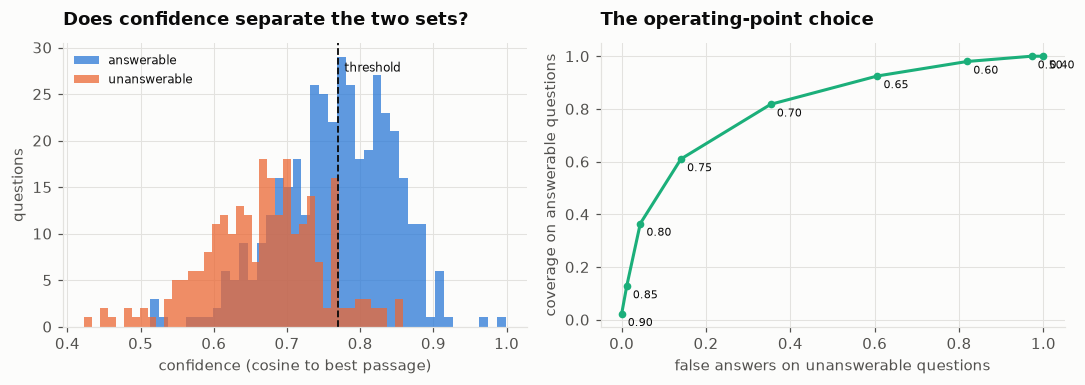

,threshold,coverage (answerable answered),false answers (unanswerable answered),precision of answering
0,0.40,1.0000,1.0000,0.6163
1,0.50,1.0000,0.9719,0.6231
2,0.60,0.9800,0.8193,0.6577
3,0.65,0.9250,0.6064,0.7102
4,0.70,0.8175,0.3534,0.7880
5,0.75,0.6100,0.1406,0.8746
6,0.80,0.3650,0.0442,0.9299
7,0.85,0.1275,0.0120,0.9444
8,0.90,0.0225,0.0000,1.0000


at most    2% false answers -> threshold 0.83, coverage 23.0%, actual false-answer rate 1.2%
at most    5% false answers -> threshold 0.80, coverage 36.5%, actual false-answer rate 4.4%
at most   10% false answers -> threshold 0.77, coverage 51.5%, actual false-answer rate 8.0%
at most   20% false answers -> threshold 0.74, coverage 65.8%, actual false-answer rate 16.5%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].hist(rows_ex[rows_ex.answerable].confidence, bins=40, alpha=.75,
             color=viz.SERIES[0], label="answerable")
axes[0].hist(rows_ex[~rows_ex.answerable].confidence, bins=40, alpha=.75,
             color=viz.SERIES[1], label="unanswerable")
axes[0].axvline(SHIP_AT, color=viz.INK, lw=1.2, ls="--")
axes[0].annotate("threshold", (SHIP_AT, axes[0].get_ylim()[1]*0.9),
                 xytext=(4, 0), textcoords="offset points", fontsize=8)
axes[0].set_xlabel("confidence (cosine to best passage)")
axes[0].set_ylabel("questions"); axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title("Does confidence separate the two sets?")

sw = threshold_sweep(rows_ex)
axes[1].plot(sw["false answers (unanswerable answered)"],
             sw["coverage (answerable answered)"], "-o", color=viz.SERIES[2], ms=4)
for _, r in sw.iterrows():
    axes[1].annotate(f"{r['threshold']:.2f}",
                     (r["false answers (unanswerable answered)"],
                      r["coverage (answerable answered)"]),
                     xytext=(4, -8), textcoords="offset points", fontsize=7)
axes[1].set_xlabel("false answers on unanswerable questions")
axes[1].set_ylabel("coverage on answerable questions")
axes[1].set_title("The operating-point choice")
plt.tight_layout(); plt.show()

display(sw)

# The operating point, chosen by naming the cost rather than maximising a score.
# F1 would weigh a wrong answer about a company's covenants equally against a
# missed one, and they are not equal: a confident wrong citation is worse than
# silence, because the citation is what makes a reader stop checking.
for budget in (0.02, 0.05, 0.10, 0.20):
    got = pick_threshold(rows_ex, max_false_answer_rate=budget)
    flag = "" if got["satisfiable"] else "   <- UNREACHABLE on this grid"
    print(f"at most {budget:>5.0%} false answers -> threshold {got['threshold']:.2f}, "
          f"coverage {got['coverage']:.1%}, actual false-answer rate "
          f"{got['false_answer_rate']:.1%}{flag}")

### The system re-scored at the operating point it would actually ship at

The table above is the system at 0.45, which was a guess written into a
constant. This one is the system at the threshold the budget above bought.

Re-scoring from the recorded rows rather than re-running is exact *in this
direction only*: raising the bar removes answers, so the answered set is a
strict subset of one already graded. Lowering it is refused by
`report_at_threshold`, because the questions below the original bar were never
answered and there is nothing there to grade.

In [6]:
CHOSEN = pick_threshold(rows_ex, max_false_answer_rate=0.10)
print(CHOSEN)

display(report_table([
    rep_ex,
    report_at_threshold(rows_ex, CHOSEN["threshold"], "extractive", pipe.abstain_at),
    report_at_threshold(rows_ex, SHIP_AT, "extractive", pipe.abstain_at),
]))

print("\nWhat the shipping row costs and buys, in one sentence:")
print(f"  answering only above {SHIP_AT:.2f} covers "
      f"{(rows_ex[rows_ex.answerable].confidence >= SHIP_AT).mean():.1%} of answerable "
      f"questions and answers "
      f"{(rows_ex[~rows_ex.answerable].confidence >= SHIP_AT).mean():.1%} of the "
      f"unanswerable ones.")

{'threshold': 0.77, 'coverage': 0.515, 'false_answer_rate': 0.0803, 'satisfiable': True}


,mode,answered (answerable),answered (unanswerable),retrieval recall@k,attribution@1,attribution@cited,citation ceiling,grounded verbatim,grounding overlap (1gram),grounding overlap (2gram),abstention AUC,median ms
0,extractive,1.000,1.0000,0.270,0.1300,0.1825,0.4815,1.0,1.0,1.0,0.8213,185.7
1,extractive @ 0.77,0.515,0.0803,0.267,0.1505,0.1990,0.5636,1.0,1.0,1.0,0.8213,185.7
2,extractive @ 0.77,0.515,0.0803,0.267,0.1505,0.1990,0.5636,1.0,1.0,1.0,0.8213,185.7



What the shipping row costs and buys, in one sentence:
  answering only above 0.77 covers 51.5% of answerable questions and answers 8.0% of the unanswerable ones.


### The threshold is a business decision, not a hyperparameter

Every row of that table is a different answer to *how wrong are we willing to
be, in exchange for how much coverage*. A credit analyst screening filings
wants high coverage and tolerates noise; anything feeding a published rating
memo wants the opposite. Picking the operating point is not the model's job,
so it is reported rather than buried in a constant.

## Where it goes wrong

Aggregates hide the interesting cases. Two lists: questions answered with the
wrong filing cited, and unanswerable questions that got answered anyway.

In [7]:
# Abstention was switched off for measurement, so "answered" here means
# "would be answered at the shipping threshold" — stated explicitly rather than
# inherited from whatever pipe.abstain_at happens to be.
served = rows_ex[rows_ex.confidence >= SHIP_AT]

wrong = served[(served.answerable) & (~served.hit_cited)]
print(f"{len(wrong)} answerable questions served at {SHIP_AT:.2f} cited the wrong passage")

# Split that failure in two, because the fix is different on each side.
never_found = wrong[~wrong.retrieved_k]
found_not_quoted = wrong[wrong.retrieved_k]
print(f"  {len(never_found):>4} — retrieval never returned the gold passage "
      f"(stage 5's problem)")
print(f"  {len(found_not_quoted):>4} — retrieval FOUND it and the answerer "
      f"quoted something else (stage 6's problem)\n")

for _, r in wrong.head(3).iterrows():
    print(f"Q  : {r['query'][:96]}")
    print(f"A  : {r['text'][:200]}")
    print(f"     confidence {r['confidence']:.3f} · gold retrieved: {r['retrieved_k']}\n")

false_ans = served[~served.answerable]
print(f"\n{len(false_ans)} unanswerable questions would be answered at "
      f"{SHIP_AT:.2f}\n")
for _, r in false_ans.sort_values("confidence", ascending=False).head(3).iterrows():
    print(f"Q  : {r['query'][:96]}")
    print(f"A  : {r['text'][:200]}")
    print(f"     confidence {r['confidence']:.3f}\n")

print("Read these. Some 'false answers' on this corpus are questions another "
      "firm genuinely also asked — a screening limitation, not a "
      "hallucination. That is what the 0.30 screen is for, and the hand audit "
      "below is what decides whether it worked.")

165 answerable questions served at 0.77 cited the wrong passage
   151 — retrieval never returned the gold passage (stage 5's problem)
    14 — retrieval FOUND it and the answerer quoted something else (stage 6's problem)

Q  : Any failure of our third-party providers to fulfill their obligations, or our failure to maintai
A  : Failure of these parties to perform as expected, or interruptions in the Company's relationships with these providers or their

provision of services to the Company, could have a material adverse effe
     confidence 0.857 · gold retrieved: False

Q  : Recent regulatory actions may adversely affect the trading price and liquidity of the warrants a
A  : A decrease in the market price of our common stock would likely adversely impact the trading price of the warrants. The issuance and sale of substantial amounts of common stock, or the perception that
     confidence 0.821 · gold retrieved: False

Q  : Legislative or regulatory tax changes related to REITs could m

## Hand-audit the negative control

The screen is a heuristic and the AUC rests entirely on it. In stage 5 an
identical-looking result was **withdrawn** after ten pairs were read by hand and
four turned out to be junk. The same discipline applies here, and it is cheap:
read the ten unanswerable questions the system was *most* confident about. If
they have real answers in the corpus, the control is still dirty and the AUC is
still optimistic — no aggregate will tell you that.

In [8]:
top = (rows_ex[~rows_ex.answerable]
       .sort_values("confidence", ascending=False).head(10))
print("The 10 'unanswerable' questions the system was most sure about.")
print("For each: is this genuinely unanswerable from a 433-firm 10-K corpus?\n")
for n, (_, r) in enumerate(top.iterrows(), 1):
    print(f"{n:>2}. conf {r['confidence']:.3f}  Q: {r['query'][:88]}")
    print(f"     A: {r['text'][:150]}\n")

print("Count how many have a real answer above. If it is more than 2 or 3, drop "
      "SCREEN to 0.25 and re-run from cell 5 — and say the audited number out "
      "loud rather than the AUC alone.")

The 10 'unanswerable' questions the system was most sure about.
For each: is this genuinely unanswerable from a 433-firm 10-K corpus?

 1. conf 0.858  Q: Acquisitions involve inherent risks that could compromise the success of the combined bu
     A: Acquisitions involve risks, including difficulties in the integration of the operations, technologies, services and products of the acquired companies

 2. conf 0.858  Q: Major disruptions to our logistics capability or to the operations of our key vendors or
     A: We may experience further disruptions in the future, and any prolonged disruptions to our manufacturing operations, supply chain and/or distribution c

 3. conf 0.851  Q: Many of our contracts are fixed-price and may be delayed or terminated or reduced in sco
     A: We enter into fixed-price contracts which could subject us to losses if we have cost overruns. While fixed-price contracts enable us to benefit from p

 4. conf 0.827  Q: We Depend on Creating New Products and Pro

## Generative mode — optional

`flan-t5-base` downloads once (~250 MB) and runs on CPU at roughly one answer
a second, so this is scored on a smaller sample. It exists to make the
faithfulness numbers mean something: extractive mode's grounding is 1.00 by
construction, so it is a control. A model that writes its own sentences can
drop below 1.00, and how far below is the actual finding.

Skip this cell if you would rather not wait — nothing downstream needs it.

In [9]:
RUN_GENERATIVE = True     # set False to skip

if RUN_GENERATIVE:
    n = 120
    # Generative mode is judged at the shipping bar, not the measuring
    # floor — flan-t5 answers are the deliverable, not a calibration input.
    pipe.abstain_at = SHIP_AT
    rep_gen, rows_gen = evaluate_rag(
        pipe, answerable.head(n), unanswerable.head(n), mode="generative")
    display(report_table([rep_ex, rep_gen]))

    # Filter on the BIGRAM column. The unigram version saturates at 1.0 on
    # this corpus and would return an empty list no matter how bad the answers
    # were — which is exactly what it did on the first run.
    bad = rows_gen[(~rows_gen.abstained) & (rows_gen.bigram < 0.6)]
    print(f"\n{len(bad)} generative answers used words absent from their sources\n")
    for _, r in bad.head(4).iterrows():
        print(f"Q : {r['query'][:88]}")
        print(f"A : {r['text'][:160]}")
        print(f"    unigram {r['overlap']:.2f} · bigram {r['bigram']:.2f}\n")
    pipe.abstain_at = 0.0
else:
    print("skipped")

generative/unanswerable: 100%|██████████| 120/120 [00:16<00:00,  7.23it/s]


,mode,answered (answerable),answered (unanswerable),retrieval recall@k,attribution@1,attribution@cited,citation ceiling,grounded verbatim,grounding overlap (1gram),grounding overlap (2gram),abstention AUC,median ms
0,extractive,1.000,1.0000,0.27,0.1300,0.1825,0.4815,1.0000,1.0,1.0,0.8213,185.7
1,generative,0.125,0.0167,0.20,0.1333,0.2000,0.6667,0.0667,1.0,1.0,0.7817,56.0



0 generative answers used words absent from their sources



## Verdict

**Extractive grounding is 1.00 by construction — a control, not an
achievement.** Quote it as proof the plumbing is right, never as proof the
system is good. Its value was in failing: 0.9850 on the first run, 0.9855 on the
bigram version of the second, both pipeline defects that a metric which could
only pass would have hidden.

**Abstention works, and the operating point is the honest headline.** Cosine
confidence separates answerable from unanswerable at **ROC-AUC 0.82**. At the
default 0.45 that separation was worthless — 99.2% of unanswerable questions got
answered — because the threshold was a constant nobody chose. Naming a budget
instead ("answer at most 10% of what we cannot answer") gives **0.77 → 51.5%
coverage at 8.0% false answers**. Half the questions refused is the price, and
saying so is the point.

**The AUC moved from 0.65 to 0.82 by fixing the negative control, not the
system.** Worth stating plainly, because it is the most transferable lesson
here: a metric can only be as good as the set it is measured against, and
"absent from the corpus" is not the same as "unanswerable" when the corpus is
10-K risk language.

**Retrieval, not answering, is the ceiling.** 292 of 327 wrong citations never
had the gold passage retrieved. A finance-domain embedder is the one-variable
experiment that would move both this stage and stage 5.

**flan-t5-base is barely generative.** 100% bigram overlap with the source
alongside 15.6% verbatim sentence containment means it is copying spans and
stopping mid-sentence, not paraphrasing. So it is a weak test of hallucination
— which is a limitation of the model, honestly stated, not a clean bill of
health for RAG.

**Next**, in order of value: FastAPI, so latency is measured under load rather
than in a notebook; then the domain embedder, re-running this and stage 5
unchanged.